# StartRight: does reset still work after normal use?
**Adnane Essoufi. Solo project. Apache-2.0.**

Reset should put a circuit in a known state. But a test can pass because the
circuit was already in that state. We need to check what happens after normal use.

Here is the test: write the other state using the circuit's normal input.
Check that the write worked. Then lower the supply, bring it back, and check reset.

We first run this test on a small latch, a circuit that stores one bit.
Then we use saved simulations of a published reset circuit and flip-flop.
A flip-flop also stores one bit, called Q.

## What we found

| Reset circuit | Requirements met in seven sampled conditions |
|---|---:|
| Published power-on reset (POR) | 3/7 |
| POR with an added digital-supply check, called the guard | 4/7 |
| Controller with a voltage reference | 7/7 |

These counts include tests that preserve data and tests where startup fails
before a write is possible. They are **not seven successful setups followed by
seven reset tests**. All use typical transistor models (TT), at -40, 27 or 125 C.
They test our chosen requirements, not a promise made by the original designers.

The reference has a cost. In one working storage test, it uses **40.3% more
energy supplied by the sources** than the original POR. In a separate working
analog-supply interruption, it uses **19.8% less**. Both count startup and all
four sources. These two tests do not tell us the lifetime energy use.

![Measured reset behavior, seven requirements and energy costs](figures/decision_overview.png)

*Saved Windows simulations. The notebook checks the saved files and repeats
their measurements. The waveform panel shows part of recovery; the checks use
the full traces.*

The contribution is the test method and code you can reuse. The reset circuits
use established ideas. These schematic simulations do not prove how fabricated
hardware retains data.

**Start here:** follow this notebook in order. It runs six new latch simulations,
then checks saved results from the larger circuits. [README.md](README.md) gives
the setup. [Explore_reset.html](Explore_reset.html) lets you explore saved results
without installing tools. A failed new run is never replaced with a saved success.

Software checks: 6 hand-computed monitor/accounting checks


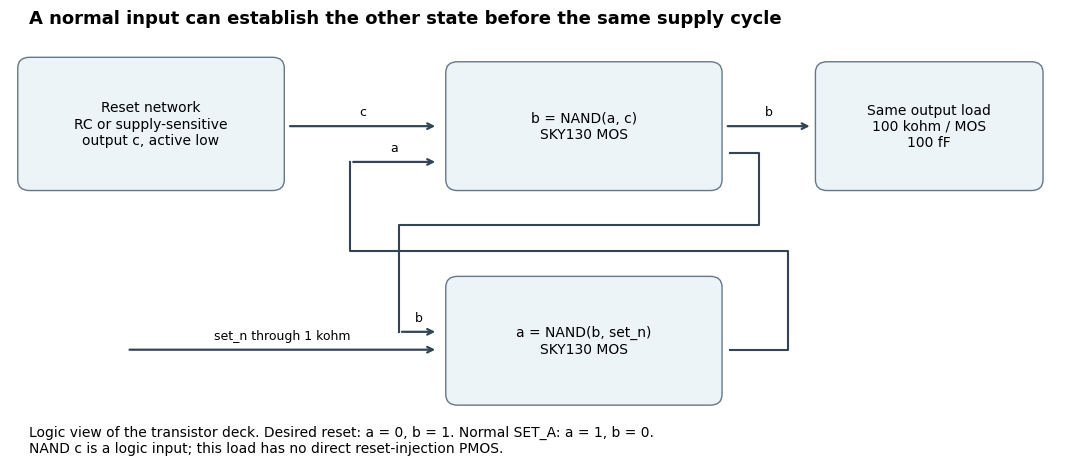

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from reset_sequence import run_sequence
from sequence_figures import connections, comparison, print_results
from check_reset_contract import checks

print("Software checks:", len(checks()), "hand-computed monitor/accounting checks")
display(connections())
plt.close("all")

## 1. Start with the expected state already stored

The latch stores two opposite voltages, a and b. Reset should make **a low and
b high**. Its normal `set_n` input can write the other state.

We compare two reset circuits on the same latch and load. The first uses a
resistor and capacitor, called RC. The second senses the supply voltage.
Timing resistors and capacitors are ideal in these simulations.

First, leave the expected state in place. The supply falls to 0.9 V for 10 us,
then returns to 1.8 V over 2 ms. Think about what a pass would show here:
the state is correct, but reset may not have changed it.

<details><summary>Exact circuit and test limits</summary>

The NAND latch follows $a=\overline{b\cdot set_n}$ and $b=\overline{a\cdot c}$.
Reset c=0 writes a=0, b=1. An active-low `set_n` command writes a=1, b=0.
The RC uses 75 Mohm and 9.0667 pF, so $\tau=680\,\mu$s.
The other circuit uses a diode-connected NMOS biased through 10 Mohm,
a CMOS inverter and a 1 pF output capacitor.

At TT/27 C, the first 1.8 V ramp lasts 430 us. The later fall takes 1 us.
The ordinary command lasts 20 us through a 1 kohm driver.
Only that command changes between the two trials.

After each ramp, a must reach 0.36 V or less and b 1.44 V or more within 1 ms.
Reset must release to c >= 1.71 V, with VDD-c <= 0.09 V, within 5 ms.
VDD must reach 1.71 V. Each observation lasts 8 ms after the ramp, with at
least 2 ms hold. The prior state must hold for 5 us before a 100 ns gap.
These are teaching limits, not a commercial specification.

</details>

In [2]:
corner = "tt"       # Supported teaching choices: tt or sf, both at 27 C.
dip_V = 0.9        # Same supply history is used again in the next cell.
retained = run_sequence(corner=corner, low_V=dip_V, command=False)
print_results(retained)

frozen_rc_sr measured observed pass: True alternate state: False


detector_10M_sr measured observed pass: True alternate state: False


Circuit | State/timing passed | Prior state checked | Other state tested | Restoration observed
RC | True | True | False | False
Supply sensing | True | True | False | False


## 2. Write the other state, then repeat the same test

Use the normal input to write a high and b low. Check the measured voltages
before the supply dip. Sending a command alone does not prove the write worked.

At the default setting, both circuits pass startup. After the write, the RC
misses reset and the supply-sensing circuit passes. Compare this with the
previous test. Its retained-state pass was valid, but it did not show restoration.

In [3]:
commanded = run_sequence(corner=corner, low_V=dip_V, command=True)
print_results(commanded)
print("Cold-start passes:", [r.get("events", [{}])[0].get("pass_contract")
                             for r in commanded["cases"]])

frozen_rc_sr measured observed pass: False alternate state: True


detector_10M_sr measured observed pass: True alternate state: True


Circuit | State/timing passed | Prior state checked | Other state tested | Restoration observed
RC | False | True | True | False
Supply sensing | True | True | True | True
Cold-start passes: [True, True]


## 3. Explain the result

The RC capacitor keeps most of its charge during the short dip. When power
returns, reset can already be inactive. The circuit can keep the wrong state.

We can predict the reset-node voltage, c, with the RC equation below. It ignores
transistor loading. SPICE includes that loading, so the two are separate checks.

For a linear supply ramp $V(u)=V_0+Su$:

$$c(u)=c_0e^{-u/\tau}+V_0(1-e^{-u/\tau})+
S\{u-\tau(1-e^{-u/\tau})\}.$$

Here u is time from the start of the ramp, c0 is the starting reset voltage,
and S is the ramp slope.

Supply sensing also draws current. Compare its energy only during the same
working startup interval, before either write. Count every source. The failed
full RC test cannot be used as a low-energy alternative.

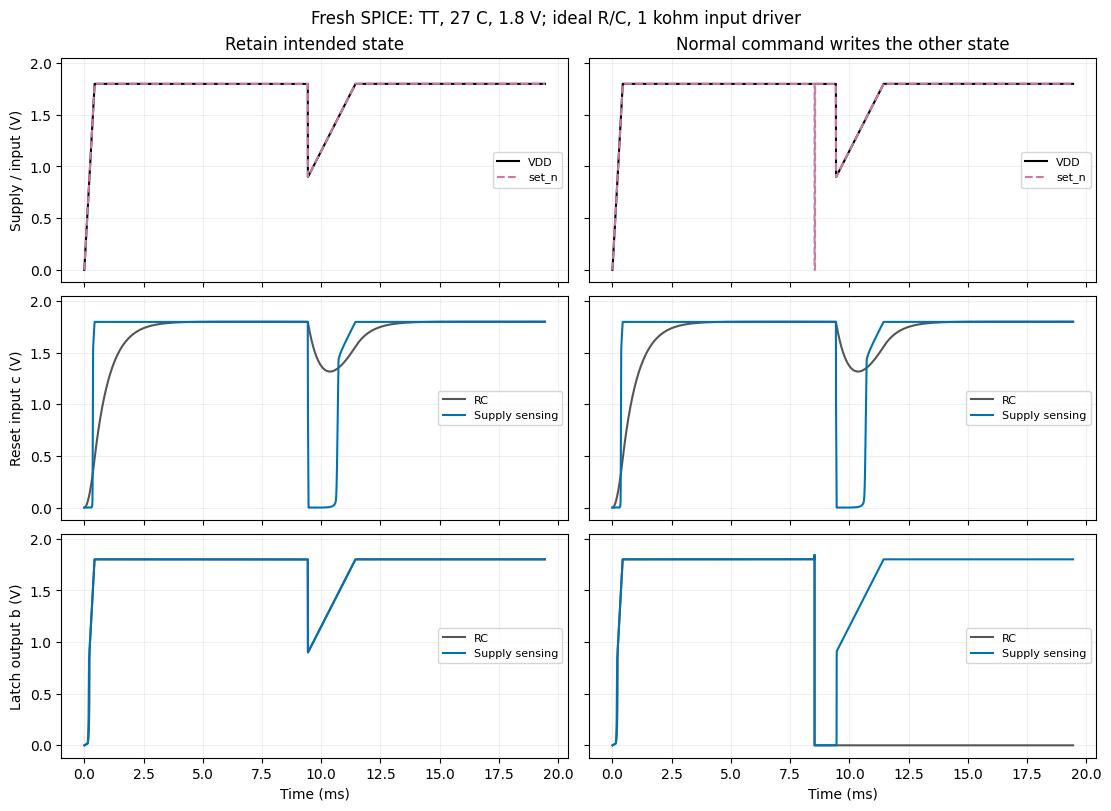

frozen_rc_sr working cold delivered work (nJ): 41.74
  Reset at recovery start, ideal RC / measured (V): 1.7862 1.7857
detector_10M_sr working cold delivered work (nJ): 46.242


In [4]:
if retained["status"] != "completed" or commanded["status"] != "completed":
    raise RuntimeError("Fresh acquisition unresolved. Inspect its logs; no saved substitute.")
display(comparison(retained, commanded))
plt.close("all")
from sequence_analysis import explain
analysis = explain(commanded)
for row in analysis["cases"]:
    work = row["working_cold_delivered_J"]
    print(row["variant"], "working cold delivered work (nJ):",
          None if work is None else round(work * 1e9, 3))
    if "ideal_recovery_initial_c_V" in row:
        print("  Reset at recovery start, ideal RC / measured (V):",
              round(row["ideal_recovery_initial_c_V"], 4),
              round(row["measured_recovery_initial_c_V"], 4))

## 4. Check the explanation with two new simulations

The 10 us low hold is short compared with the 680 us RC time constant. An
unloaded capacitor loses only about 1.46% of its voltage above the low supply
during that hold. Lowering the supply does not instantly discharge the capacitor.

The next cell predicts c for two fixed dips, 0.6 V and 1.2 V. It saves both
predictions before running either simulation. R, C and timing stay the same.
The allowed difference is 20 mV, chosen for this teaching check.

Read the two results separately: **did the voltage prediction agree, and did
reset restore the state?** A close voltage prediction cannot turn a reset miss
into a pass. Two points do not prove a voltage range or a hardware error bound.
[MECHANISM.md](MECHANISM.md) records the saved results and commands.

Hand-solvable mechanism checks: 3
Predictions written before either new acquisition:
dip 0.6 V -> predicted initial reset c 1.781611 V
dip 1.2 V -> predicted initial reset c 1.790804 V


frozen_rc_sr measured observed pass: False alternate state: True


frozen_rc_sr measured observed pass: False alternate state: True


| Dip, V | Predicted c, V | Measured c, V | Error, mV | Node check | Recovery met |
|---:|---:|---:|---:|---|---|
| 0.6 | 1.781611 | 1.780938 | -0.673 | True | False |
| 1.2 | 1.790804 | 1.790542 | -0.263 | True | False |

At the main 0.9 V dip (tt), the retained/commanded pair has a maximum measured supply difference of 0.0000 mV and recovery-reset difference of 0.0015 mV.
The ordinary command changes which stored state must be restored. A similar reset waveform can therefore accompany a retained-state pass and an exercised restoration miss.

The node check uses the predeclared 20 mV criterion. It does not predict latch switching or certify a reset threshold. Every result, including a failed prediction or unresolved acquisition, remains visible.

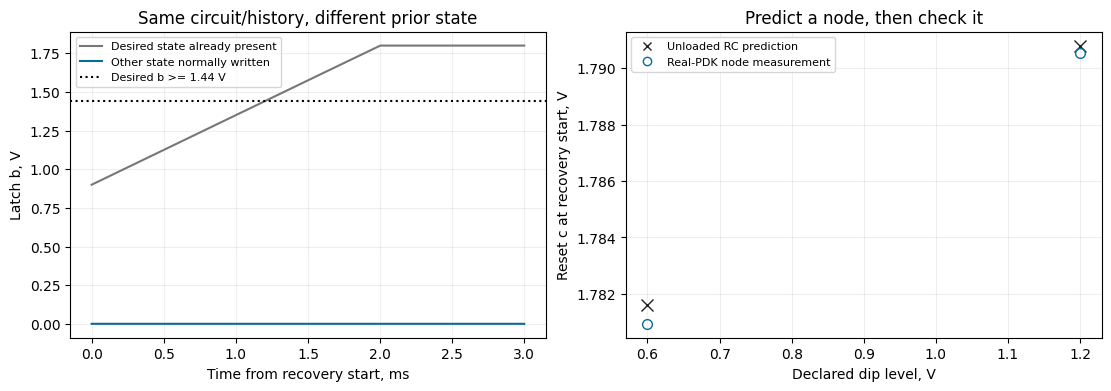

Raw-vector and rejection checks: 11


In [5]:
from mechanism_lab import run_lab, report_markdown, figure as mechanism_figure
from check_mechanism_lab import checks as mechanism_checks

print("Hand-solvable mechanism checks:", mechanism_checks())
mechanism = run_lab(retained, commanded)  # Two new RC acquisitions; all results retained.
display(Markdown(report_markdown(mechanism)))
display(mechanism_figure(mechanism, retained, commanded))
plt.close("all")
print("Raw-vector and rejection checks:", mechanism_checks(mechanism, retained, commanded))


## 5. Try the same question on published circuits

This section uses **saved simulations**, not new SPICE runs. The audit checks
the saved files, rebuilds their circuit decks and repeats the measurements.

The published [Efabless POR](https://github.com/efabless/sky130_ef_ip__simple_por/tree/d8a9581533238bdb99cb0389fd4387587969dc12)
drives an unchanged [SKY130 flip-flop](https://github.com/google/skywater-pdk-libs-sky130_fd_sc_hd/blob/ac7fb61f06e6470b94e8afdf7c25268f62fbd7b1/cells/dfrtp/sky130_fd_sc_hd__dfrtp_1.spice).
Its analog supply is AVDD=3.3 V. Its output and the flip-flop use DVDD=1.8 V.
Normal clock and data inputs write Q=1. Reset should return Q to 0.

At TT/27 C, a 1 ms interruption of the digital supply returns Q to 1.
An interruption of the analog supply restores Q=0 while digital power remains
available. Starting with Q=0 would hide this difference. Without an interruption,
the correct result is to keep Q=1.

These are our integration tests, beyond the source project's startup example.
They do not establish a defect in that project.

<details><summary>Measurement and model limits</summary>

Both rails must reach 95% of nominal. Q must reach 0.36 V or less and reset-bar
1.71 V or more within 12 ms after the ramp, with at least 1 ms hold.
A separate powered-reset pulse check is not required for every observed
restoration. A separately coded threshold check agrees with the shared monitor.

The models disable gate tunnelling. The flip-flop keeps its source schematic's
zero diffusion geometry and NRD/NRS. A zero-volt terminal does not prove that
every internal state has become the same as a cold start. **Hardware retention
is unverified.** [EVIDENCE.md](EVIDENCE.md) keeps the source assumptions and
unresolved runs.

</details>

PASS: 17 complete POR traces remeasured; 14 unresolved attempts retained.


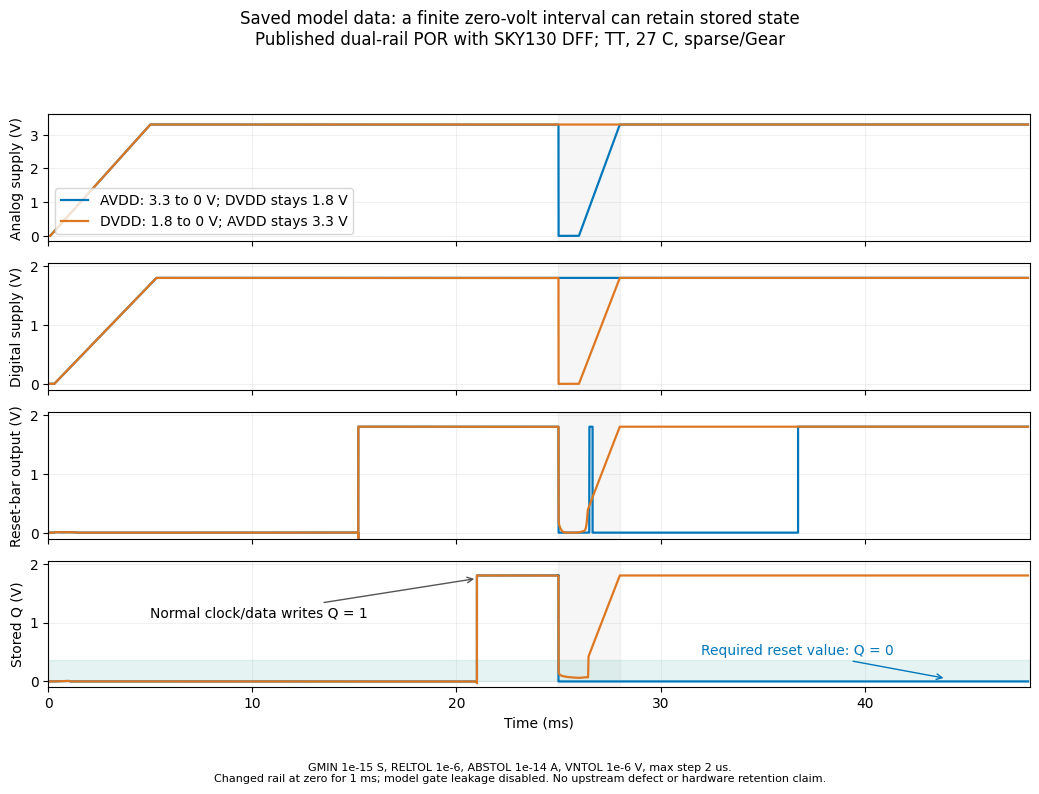

In [6]:
from por_evidence import audit as audit_por
from por_figures import show as show_por
saved_por = audit_por()   # Saved vectors, not new SPICE.
display(show_por(saved_por))
plt.close("all")

## 6. Add a supply check only when it is needed

The guard checks DVDD separately. It allows reset to release only when both
it and the original POR allow it. It uses nine MOS devices, a 40 Mohm resistor,
20 fF and 1 pF capacitors. It is a fixed conventional circuit.

In the saved short recovery, the guard returns Q to 0 after the write and the
original misses. In the slow recovery, both work. Both also keep Q=1 when
there is no interruption, so the guard does not simply erase every write.

In the smaller-step **working slow-recovery pair**, the guard uses about 1.303%
more supplied energy. That includes startup, both rails and the input sources.
The failed short-recovery original gets no energy ranking.
This slow-recovery cost is separate from the storage cost used below.

PASS: all 22 guard traces regenerated and remeasured.


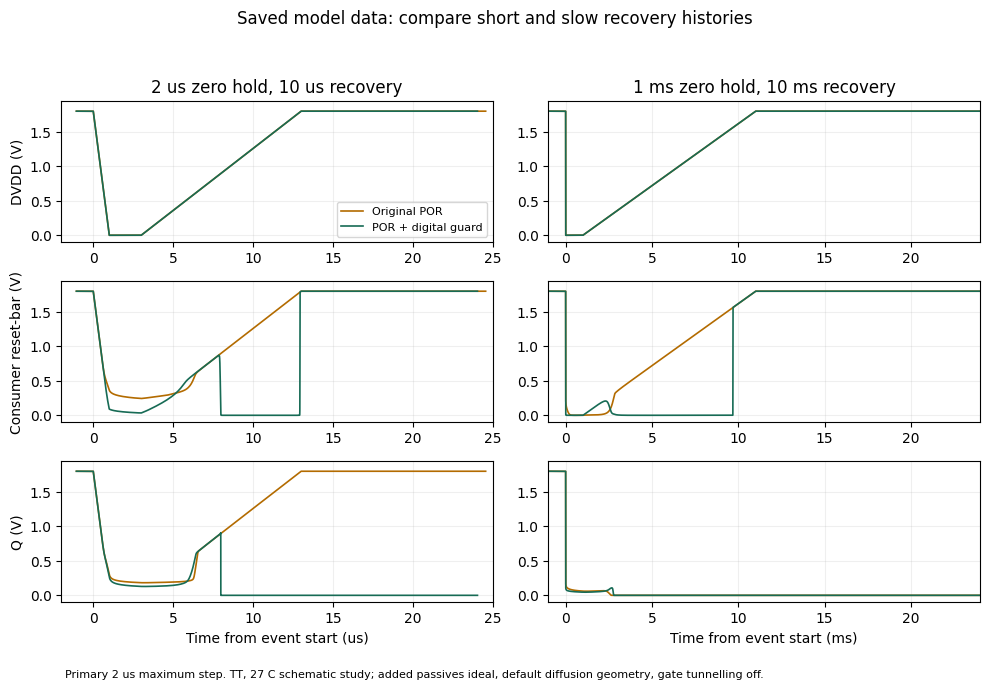

original working slow-history source work (uJ): 0.947392
digital_guard working slow-history source work (uJ): 0.959735


In [7]:
from guard_evidence import audit as audit_guard, policy_evidence
from guard_figures import show as show_guard
saved_guard = audit_guard()  # All 22 saved acquisitions, including refinements.
display(show_guard(saved_guard))
plt.close("all")
guard_rows = policy_evidence(saved_guard)
for variant in ("original", "digital_guard"):
    row = next(r for r in guard_rows["rows"]
               if r["condition"] == "slow_zero" and r["variant"] == variant)
    print(variant, "working slow-history source work (uJ):",
          round(row["source_work_delivered_J"] * 1e6, 6))

## 7. Match the circuit to the requirements

The original POR and guard have limits. At -40 C, neither releases reset in
the saved test, so Q=1 is never written. At 125 C, both write Q=1 but miss
reset after the 1.35 V dip. These are different failures.

The reference controller meets all seven sampled requirements. It uses a
self-biased voltage reference and transistor comparator. All three choices
drive the same flip-flop, with the same inputs, 10 fF load and matched supplies.
The next cell audits **56 saved runs** and reports their results.

First require correct behavior. Then compare the working choices using the
same 27 C storage test. If evidence is missing, return `None`.
This rule does not predict lifetime energy use.

<details><summary>How the reference works</summary>

PNP $V_{BE}$ and $\Delta V_{BE}$ change in opposite directions with temperature.
The reference combines them. A startup circuit brings up the self-biased loop.
A 220 kohm / 1 Mohm divider feeds the comparator, suggesting a balance near
$1.22V_{ref}$, about 1.50 V at the sampled settled references.
That estimate is not a measured switching threshold or hysteresis specification.
Startup overshoot reaches 1.633 V.

[Reference_tradeoff.ipynb](Reference_tradeoff.ipynb) explains the circuit and sources.
[APPLICABILITY.md](APPLICABILITY.md) keeps the earlier temperature and isolated
DC checks. Those isolated checks do not qualify the complete circuit.

</details>

PASS: all 56 saved reference acquisitions regenerated and remeasured.


Lesson checks: {'status': 'passed', 'scope': 'Measured-data lesson checks; no new transistor run or human-learning evidence', 'choices': {'limited': 'original', 'nominal_reset': 'digital_guard', 'expanded': 'reference_supervisor', 'unmeasured': None}, 'questions': 4, 'bad_cold_interpretation_rejected': True, 'unattempted_not_scored': True, 'storage_distinct_from_restoration': True, 'missing_evidence_abstains': True, 'unknown_inputs_rejected': True}


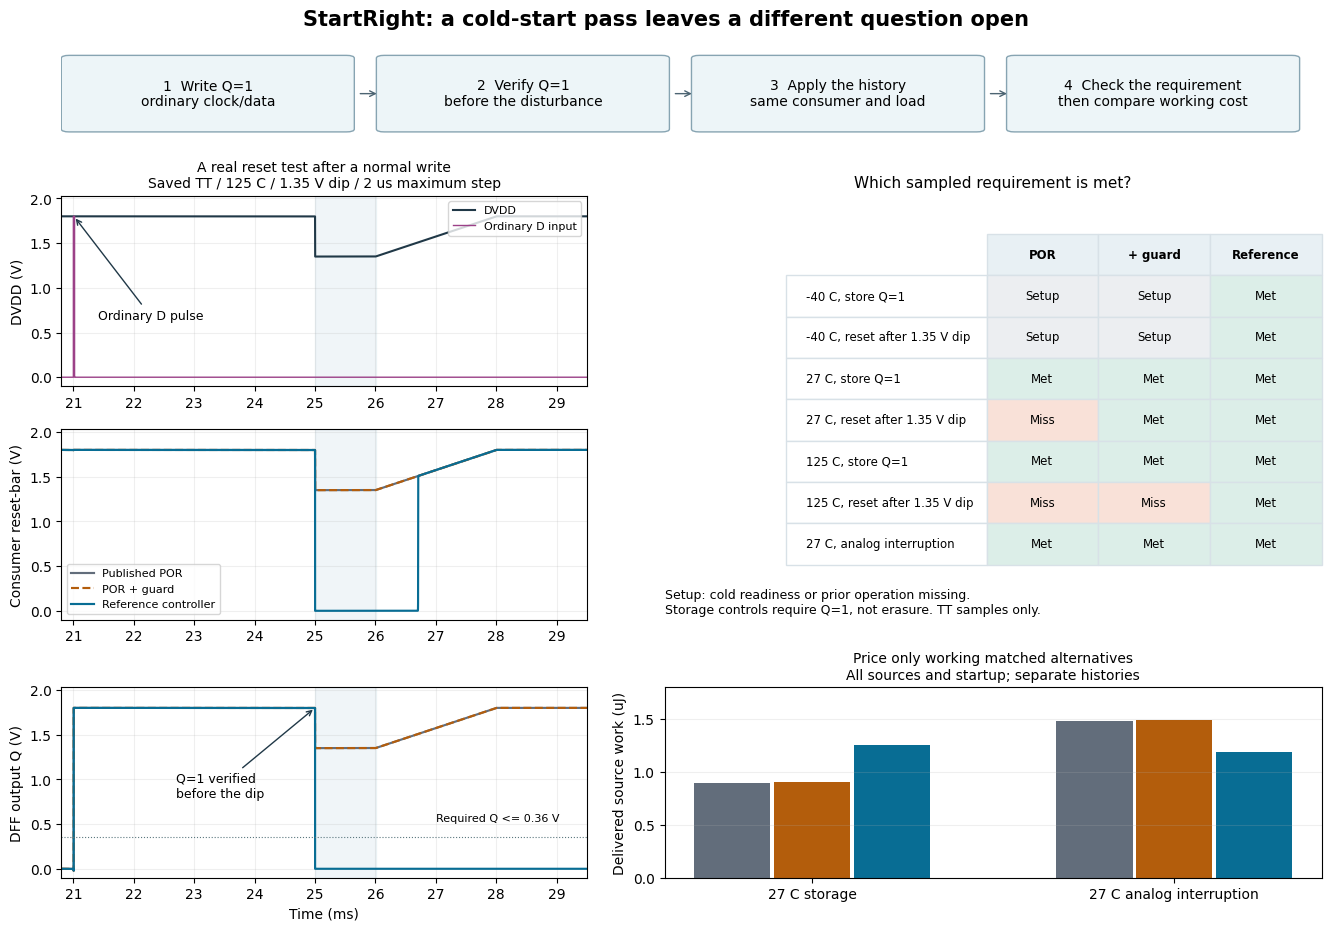

| Sampled TT requirement | Published POR | POR + guard | Reference |
|---|---|---|---|
| -40 C, store Q=1 | Setup missing | Setup missing | Met |
| -40 C, reset after 1.35 V dip | Setup missing | Setup missing | Met |
| 27 C, store Q=1 | Met | Met | Met |
| 27 C, reset after 1.35 V dip | Missed | Met | Met |
| 125 C, store Q=1 | Met | Met | Met |
| 125 C, reset after 1.35 V dip | Missed | Missed | Met |
| 27 C, analog interruption | Met | Met | Met |

**Met** means the declared requirement, including setup. A storage row requires Q=1 to remain stored.
**Setup missing** is not an exercised reset miss. Seven development conditions do not qualify a temperature range.

| Working matched history | Published POR, uJ | Guard, uJ | Reference, uJ |
|---|---:|---:|---:|
| 27 C storage | 0.894466 | 0.906937 | 1.255022 |
| 27 C analog interruption | 1.480795 | 1.493371 | 1.187545 |

All four independent sources and startup are counted. The two histories are separate comparisons, not a usage distribution.

limited ['nominal_storage'] -> original
nominal_reset ['nominal_storage', 'nominal_shallow'] -> digital_guard
expanded ['nominal_storage', 'cold_shallow', 'hot_shallow', 'trough_cold_storage', 'trough_hot_storage'] -> reference_supervisor
unmeasured ['nominal_storage', 'unmeasured_short_zero'] -> None


In [8]:
from reference_evidence import audit as audit_reference
from lesson_decision import overview, summary_markdown, PRESETS, decision, feedback, OPTIONS
from check_lesson_decision import checks as lesson_checks

saved_reference = audit_reference()  # All 56 saved acquisitions, not fresh SPICE.
print("Lesson checks:", lesson_checks(saved_reference))
display(overview(saved_reference))
plt.close("all")
display(Markdown(summary_markdown(saved_reference)))
for name, histories in PRESETS.items():
    print(name, histories, "->", decision(saved_reference, histories)["selected"])


## 8. Check your reading, then choose a controller

For each result, decide what happened. Was the other state written first?
Did reset restore it? Or was the test meant to preserve data?

Put an answer code in `answers` and rerun the cell. Blank answers are not scored.
The feedback points to the measured evidence. The [browser page](Explore_reset.html)
offers the four saved-data questions with buttons and menus.

Then edit `required_histories`. The selector rules out circuits that lack a
required result and compares storage energy among those that remain.
Read why each circuit was ruled out. An unmeasured requirement must return `None`.

In [9]:
print("Answer codes:")
for code, explanation in OPTIONS.items():
    print(code, ":", explanation)
answers = {
    "retained_rc": None,
    "cold_original": None,
    "hot_original": None,
    "hot_reference": None,
    "storage_control": None,
}
display(Markdown(feedback(saved_reference, answers, retained=retained)))

required_histories = ["nominal_storage", "nominal_shallow"]
choice = decision(saved_reference, required_histories)
print("Selected:", choice["selected"], "at anchor:", choice["cost_anchor"])
for candidate in choice["candidates"]:
    print(candidate["variant"], "eligible:", candidate["eligible"],
          "anchor uJ:", round(candidate["anchor_uJ"], 6),
          "reasons:", candidate["reasons"])


Answer codes:
retention_only : Restoration not exercised: desired state was already present
setup_missing : The other state was not written
reset_missed : The other state was written, but reset missed
restoration_observed : Reset changed the written state to the target within the test limits
storage_preserved : The stored data was kept in the no-event test
unresolved : Simulation incomplete; no verdict


**Fresh RC latch: no ordinary SET_A command**

Choose an answer code and rerun this cell. No answer has been scored.



**Published POR: -40 C, reset after 1.35 V dip**

Choose an answer code and rerun this cell. No answer has been scored.



**Published POR: 125 C, reset after 1.35 V dip**

Choose an answer code and rerun this cell. No answer has been scored.



**Reference controller: 125 C, reset after 1.35 V dip**

Choose an answer code and rerun this cell. No answer has been scored.



**Published POR: 27 C, store Q=1**

Choose an answer code and rerun this cell. No answer has been scored.



0/0 attempted answers agree with the recorded evidence. This is exercise feedback, not a human learning study.

Selected: digital_guard at anchor: nominal_storage
original eligible: False anchor uJ: 0.894466 reasons: ['nominal_shallow: requirement not met']
digital_guard eligible: True anchor uJ: 0.906937 reasons: []
reference_supervisor eligible: True anchor uJ: 1.255022 reasons: []


## 9. Use the check on your own signals

The monitor takes named signals, voltage limits and time windows. It does not
assume a latch or a fixed file-column order.

The next cell maps the new latch data to a one-output example. It checks b only;
the full test above checks both a and b. It reuses the same run, so this is an
adapter example, not another circuit experiment.

For your circuit, define the desired state. Write a reachable different state
through normal inputs and verify it before the supply event. Add a test with
no event to check that stored data is preserved. [REUSE.md](REUSE.md) explains
the interface. Keep an incomplete run separate from a measured circuit failure.

In [10]:
from reset_contract import Band, Window, evaluate
from sequence_circuits import extended_history

points, windows = extended_history(commanded["scenario"], commanded["contract"])
V = commanded["scenario"]["supply_V"]
before = points[4][0] - 1e-7
for row in commanded["cases"]:
    d = np.loadtxt(Path(commanded["output_dir"]) / "raw" /
                   row["case"] / "cold.dat", skiprows=1)
    result = evaluate(
        d[:, 0], {"vdd": d[:, 5], "q": d[:, 2],
                  "reset_n": d[:, 3], "release_gap": d[:, 5] - d[:, 3]},
        supply_points=points,
        windows=[Window(w["id"], w["start_s"], w["ramp_end_s"], w["stop_s"])
                 for w in windows],
        state_bands=[Band("vdd", lower=.95*V), Band("q", lower=.8*V)],
        release_bands=[Band("vdd", lower=.95*V), Band("reset_n", lower=.95*V),
                       Band("release_gap", upper=.05*V)],
        state_delay_s=.001, release_delay_s=.005, hold_s=.002,
        precondition_interval=(before-5e-6, before),
        prior_bands=[Band("q", upper=.2*V)],
        alternate_bands=[Band("q", upper=.2*V)])
    print(row["configuration"]["id"], "one-output adapter:",
          {k: result[k] for k in ("observed_pass", "declared_precondition_verified",
                                  "alternate_state_exercised", "sampled_restoration_observed")})

frozen_rc_sr one-output adapter: {'observed_pass': False, 'declared_precondition_verified': True, 'alternate_state_exercised': True, 'sampled_restoration_observed': False}


detector_10M_sr one-output adapter: {'observed_pass': True, 'declared_precondition_verified': True, 'alternate_state_exercised': True, 'sampled_restoration_observed': True}


## What to take from this lesson

A passing final state is not enough to show restoration. Check the state before
the event. A correct voltage prediction is also separate from a working reset.

Try another `dip_V`, then rerun both trial cells and the analysis. A pass at one
new setting only supports that setting. For the published circuits, add an
unmeasured requirement and explain why no choice is supported.

These are finite schematic simulations with ideal added passives. Model and
geometry limits stay with each example. Hardware retention, noise immunity,
extracted layout and full process/voltage/temperature coverage are unverified.
The exercises have not been evaluated with an independent human learner.

## Further reading and sources

[START_HERE.md](START_HERE.md) maps the results to their evidence.
[Reference_tradeoff.ipynb](Reference_tradeoff.ipynb) explains the reference circuit.
[EVIDENCE.md](EVIDENCE.md) lists the saved studies, including failed and incomplete
runs. The older sizing and temperature studies remain optional supporting data.

[Analog Devices, Power-On Reset and Related Supervisory Functions, 2004](https://www.analog.com/en/resources/technical-articles/poweron-reset-and-related-supervisory-functions.html)
explains supply-sensitive reset and RC limits.
[Nalam et al., DATE 2011](https://past.date-conference.com/proceedings-archive/2011/DATE11/PDFFILES/05.3_1.PDF)
discusses state-write limits and observation criteria.
[Wang, Chen and Geiger, ISCAS 2013](https://class.ece.iastate.edu/vlsi2/docs/Papers%20Done/2013-05-ISCAS-YW.pdf)
explains why successful starts do not prove removal of unwanted equilibria.
Our finite tests do not find every state or replace circuit continuation.

[SKY130 source](https://github.com/google/skywater-pdk-libs-sky130_fd_pr/tree/f62031a1be9aefe902d6d54cddd6f59b57627436),
[THIRD_PARTY_NOTICES.md](THIRD_PARTY_NOTICES.md) and `dependency_manifest.json`
record model and tool sources. AI assistance was used for code and explanations.